# 07 · Taste archetypes — the zodiac feature without the labels

The supervised zodiac classifier does not work. Measured on the real scrape with
cluster-grouped cross-validation, balanced accuracy lands between **0.109 and 0.121
against a 0.083 chance rate** — 1.31× to 1.45×, depending on which features you feed it.
A real edge, and far too small to present to someone as a fact about them.

The cause is the labels, not the models. On identical features and identical
methodology, predicting **genre** reaches about 7.3× chance while predicting **zodiac**
reaches about 1.75×. The audio carries plenty of information; it just does not carry
what a stranger decided an "Aries song" was.

So this notebook stops predicting the label. It clusters the real catalog into twelve
audio archetypes and attaches the sign names through a documented mapping. The user sees
the same thing — the same mix, the same pie chart, the same lift framing — but the thing
underneath is now well defined. No labels means nothing to leak, no curator to disagree
with, and no accuracy claim to defend.

The notebook's job is to find out whether that is actually *better*, or merely harder to
criticise. It ends up somewhere in between, and §4 is the uncomfortable part.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, features as F
from lovify_ml import archetypes as A, viz

pd.set_option("display.width", 200, "display.max_columns", 40)

catalog = data.load_catalog()
print(f"\n{len(catalog):,} tracks  ·  {catalog[S.GENRE].nunique():,} distinct genres")

[data] REAL catalog: 586,672 tracks from tracks.csv

586,672 tracks  ·  3,629 distinct genres


## 1 · How many archetypes does the data actually want?

Twelve is a product requirement inherited from the zodiac. Before imposing it, it is
worth asking what the catalog would choose on its own — and being honest about the gap.

Silhouette score measures how well separated the clusters are: 1.0 is perfectly
distinct, 0 is no structure at all. Fitted on a 60k sample, scored on a separate 20k
probe.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaler = F.fit_scaler(catalog)
Z_fit = F.scale(catalog.sample(min(60_000, len(catalog)), random_state=1), scaler)
probe = catalog.sample(min(20_000, len(catalog)), random_state=0)
Z_probe = F.scale(probe, scaler)

rows = []
for k in [2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 20]:
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(Z_fit)
    rows.append({"k": k,
                 "inertia_per_track": km.inertia_ / len(Z_fit),
                 "silhouette": silhouette_score(Z_probe, km.predict(Z_probe),
                                                sample_size=8000, random_state=0)})
sweep = pd.DataFrame(rows)
sweep.round(4)

,k,inertia_per_track,silhouette
0,2,7.9893,0.2243
1,3,7.0549,0.2458
2,4,6.3909,0.2115
3,5,5.8359,0.1788
4,6,5.4176,0.1803
5,8,4.8283,0.1609
6,10,4.3532,0.1638
7,12,4.0722,0.1597
8,14,3.8810,0.1427
9,16,3.7309,0.1416


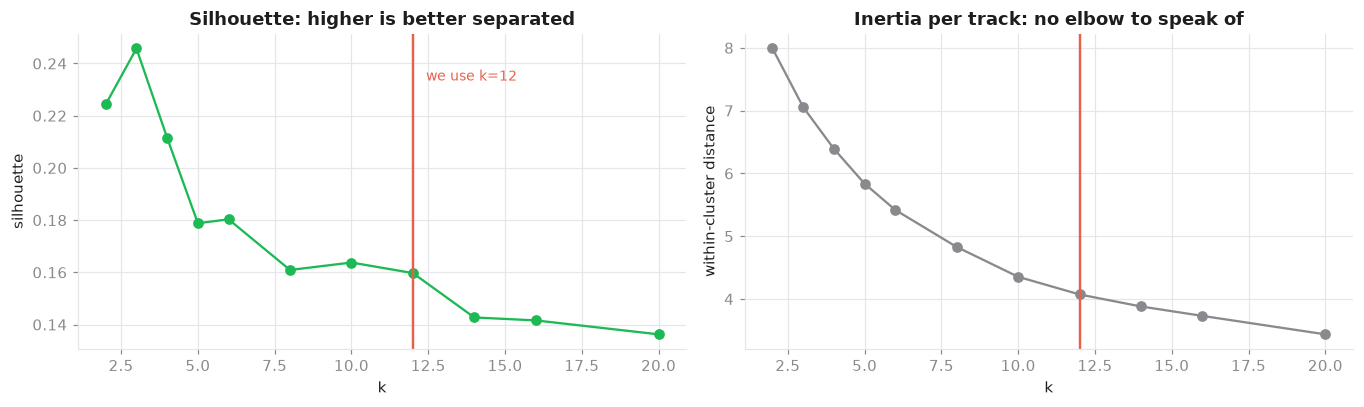

best silhouette : k=3  (0.2458)
at k=12         : 0.1597   (65% of the best)


In [3]:
best = sweep.loc[sweep.silhouette.idxmax()]
at12 = float(sweep.loc[sweep.k == 12, "silhouette"].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].plot(sweep.k, sweep.silhouette, "o-", color=viz.ACCENT)
axes[0].axvline(12, color=viz.WARN, lw=1.6)
axes[0].text(12.3, sweep.silhouette.max() * 0.95, " we use k=12", color=viz.WARN, fontsize=9)
axes[0].set_title("Silhouette: higher is better separated")
axes[0].set_xlabel("k"); axes[0].set_ylabel("silhouette")

axes[1].plot(sweep.k, sweep.inertia_per_track, "o-", color=viz.MUTED)
axes[1].axvline(12, color=viz.WARN, lw=1.6)
axes[1].set_title("Inertia per track: no elbow to speak of")
axes[1].set_xlabel("k"); axes[1].set_ylabel("within-cluster distance")
plt.tight_layout(); plt.show()

print(f"best silhouette : k={int(best.k)}  ({best.silhouette:.4f})")
print(f"at k=12         : {at12:.4f}   ({at12/best.silhouette:.0%} of the best)")

Two things to take from this, and neither is comfortable.

**The data wants k=3, not 12.** At twelve we retain about 65% of the best achievable
separation. We are imposing a twelve-way split because the product needs twelve signs,
not because twelve groups exist.

**More importantly, the absolute values are low everywhere** — nothing above 0.25
across the entire range. Audio-feature space is a **continuum, not a set of clumps**.
There are no natural kinds of music here waiting to be discovered; there is a cloud, and
any partition of it is a convenience.

That is a real limitation and it should be stated plainly rather than buried. What it
rules out is the claim "we found twelve types of listener." What it still permits is
"here is where your taste sits relative to everyone else's" — which is all the product
needs, and all §5 claims.

## 2 · The twelve archetypes

Clustering runs on **scaled** features. This is not a detail: on the real catalog
`duration_ms` outweighs the bounded features by roughly 38 billion to one, so k-means on
raw columns would partition the catalog by song length and produce twelve meaningless
duration bands.

Names come from `archetypes.SIGN_TEMPLATES` — an explicit table describing each sign as
a direction in feature space — matched to clusters one-to-one by the Hungarian
algorithm. That mapping is a **design choice, not a finding**. Nothing validates it and
nothing could; there is no ground truth for what an Aries sounds like. It exists so the
naming is reproducible rather than someone eyeballing twelve clusters and picking names
that sound nice.

In [4]:
model = A.fit_archetypes(catalog, k=12, seed=0)
A.describe(model)

,archetype,defining_features,catalog_share,examples
0,Leo,"danceability +0.97, valence +0.91, energy +0.69",0.2070,Astronaut In The Ocean — Masked Wolf; telepatí...
1,Libra,"acousticness +0.81, valence +0.67, energy -0.54",0.1275,What You Know Bout Love — Pop Smoke; Memories ...
2,Pisces,"valence -0.83, instrumentalness -0.37, energy ...",0.1246,drivers license — Olivia Rodrigo; The Business...
3,Scorpio,"acousticness -1.04, energy +1.00, loudness +0.82",0.1140,Peaches (feat. Daniel Caesar & Giveon) — Justi...
4,Cancer,"energy -1.33, acousticness +1.15, valence -1.02",0.1055,"lovely (with Khalid) — Billie Eilish, Khalid; ..."
5,Aries,"tempo +1.70, energy +0.54, loudness +0.46",0.1005,Blinding Lights — The Weeknd; Leave The Door O...
6,Sagittarius,"liveness +2.90, energy +0.49, danceability -0.30",0.0559,Save Your Tears — The Weeknd; Good Days — SZA;...
7,Gemini,"speechiness +4.25, loudness -1.03, liveness +0.91",0.0422,Carry On — XXXTENTACION; Dead and Cold — SadBo...
8,Virgo,"instrumentalness +2.63, loudness -2.09, energy...",0.0416,Clean White Noise - Loopable with no fade — Er...
9,Taurus,"instrumentalness +2.55, acousticness +1.20, en...",0.0405,everything i wanted — Billie Eilish; YKWIM? — ...


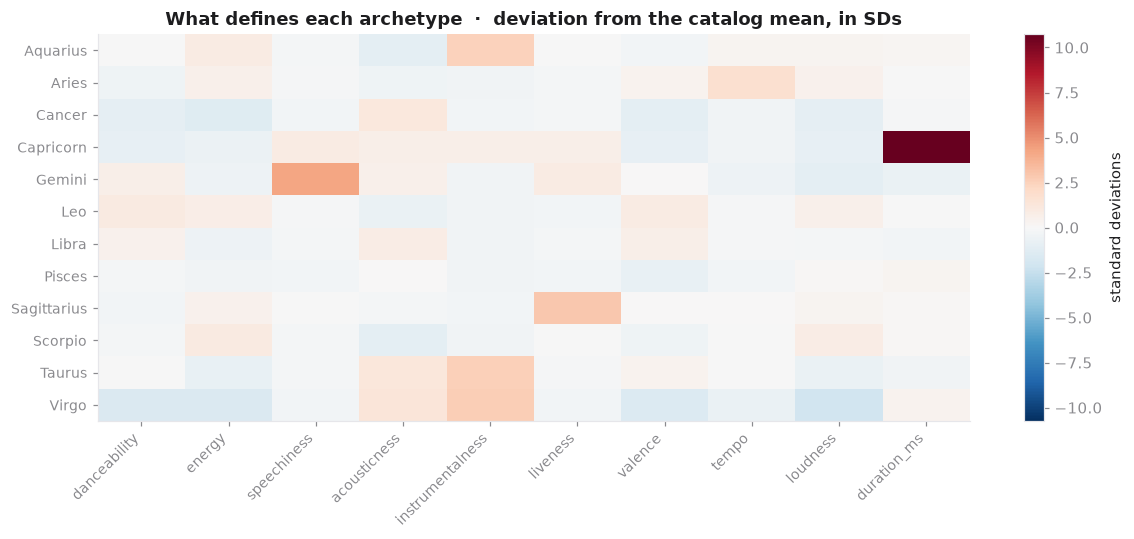

In [5]:
dev = model.deviations.copy()
dev.index = model.names
dev = dev.loc[sorted(dev.index)]

fig, ax = plt.subplots(figsize=(11, 5))
lim = float(np.abs(dev.to_numpy()).max())
im = ax.imshow(dev.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(dev.columns)))
ax.set_xticklabels(dev.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(dev))); ax.set_yticklabels(dev.index, fontsize=9)
ax.set_title("What defines each archetype  ·  deviation from the catalog mean, in SDs")
ax.grid(False)
plt.colorbar(im, ax=ax, label="standard deviations")
plt.tight_layout(); plt.show()

### Is any of these a junk bucket?

The catalog is archival and multilingual — its largest genres include `adult standards`,
`hoerspiel` (German radio drama) and `classic bollywood`. A clustering of *audio*
features has no way to know that some of these recordings are not music. Checking the
genre composition of the clusters with the most extreme feature deviations:

In [6]:
labels = model.kmeans.predict(F.scale(catalog, model.scaler, model.features))
tagged = catalog.assign(archetype=[model.names[i] for i in labels])

rows = []
for name in model.names:
    sub = tagged[tagged.archetype == name]
    top = sub[S.GENRE].value_counts(normalize=True).head(3)
    rows.append({"archetype": name, "tracks": len(sub),
                 "top genres": ", ".join(f"{g} {v:.0%}" for g, v in top.items())})
pd.DataFrame(rows).sort_values("tracks", ascending=False).reset_index(drop=True)

,archetype,tracks,top genres
0,Leo,121470,"unknown 8%, latin 3%, dance pop 3%"
1,Libra,74811,"unknown 13%, adult standards 8%, classic bolly..."
2,Pisces,73103,"unknown 7%, c-pop 6%, album rock 4%"
3,Scorpio,66906,"unknown 6%, album rock 5%, alternative metal 3%"
4,Cancer,61865,"adult standards 14%, unknown 11%, classical 7%"
5,Aries,58983,"unknown 7%, album rock 4%, adult standards 3%"
6,Sagittarius,32788,"unknown 8%, album rock 6%, adult standards 4%"
7,Gemini,24749,"hoerspiel 39%, unknown 26%, kleine hoerspiel 8%"
8,Virgo,24414,"classical 31%, unknown 12%, adult standards 6%"
9,Taurus,23774,"unknown 23%, adult standards 7%, classic bolly..."


In [7]:
spoken = ["hoerspiel", "kleine hoerspiel", "barnsagor", "horspiel"]
for name in model.names:
    sub = tagged[tagged.archetype == name]
    share = sub[S.GENRE].isin(spoken).mean()
    if share > 0.15:
        print(f"{name}: {share:.0%} spoken-word audio, not music "
              f"({len(sub):,} tracks, speechiness "
              f"{model.deviations.iloc[model.names.index(name)]['speechiness']:+.2f} SD)")
        print("  most POPULAR tracks here (what describe() surfaces):")
        for t in model.examples[name][:3]:
            print(f"    {t}")
        print("  the spoken-word mass that actually fills the cluster:")
        for _, r in sub[sub[S.GENRE].isin(spoken)].head(3).iterrows():
            print(f"    {r[S.TRACK_NAME][:48]} — {r[S.ARTIST][:22]}  [{r[S.GENRE]}]")

Gemini: 52% spoken-word audio, not music (24,749 tracks, speechiness +4.25 SD)
  most POPULAR tracks here (what describe() surfaces):
    Carry On — XXXTENTACION
    Dead and Cold — SadBoyProlific
    TPL x Fumez The Engineer - Plugged In Freestyle — Fumez The 
  the spoken-word mass that actually fills the cluster:
    Teil 1 - Die Pyramide des Sonnengottes - Karl Ma — Karl May, Heiko Grauel  [hoerspiel]
    Teil 131 - Die Pyramide des Sonnengottes - Karl  — Karl May, Heiko Grauel  [hoerspiel]
    Teil 64 - Die Pyramide des Sonnengottes - Karl M — Karl May, Heiko Grauel  [hoerspiel]


There it is. One archetype is **over half spoken-word recordings** — German radio
drama and Swedish children's stories — swept up because audiobooks have extreme
`speechiness` and the clustering only sees audio.

Note the trap in how this presents: the cluster's *most popular* tracks are rap, because
rap also scores high on speechiness and rap is what gets streamed. So `describe()`, which
surfaces examples by popularity, makes the cluster look like a hip-hop archetype while
half its mass is radio drama. A quick eyeball of the examples would have missed this
entirely — it only showed up by counting genres.

This is a property of *this catalog*, not of music, and it has a cheap fix: filter
non-music genres before fitting, or exclude tracks above a speechiness threshold. It is
flagged rather than silently patched because it is exactly the kind of thing that
reaches production as "why does Spotify think I'm a Gemini" when a user's one audiobook
dominates their mix.

## 3 · Stability — the question the whole idea rests on

If refitting the model reshuffles everyone's archetype, then an archetype is not a taste
profile. It is noise with a zodiac sign printed on it.

Adjusted Rand index compares two clusterings of the same tracks: 1.0 means identical,
0 means no better than random agreement.

In [8]:
stab = A.stability(catalog, k=12, seeds=(0, 1, 2, 3, 4))
print(f"track-level agreement across 5 refits (probe n={stab['n_probe']:,})")
print(f"  mean pairwise ARI : {stab['mean_ari']:.3f}")
print(f"  worst pair        : {stab['min_ari']:.3f}")

track-level agreement across 5 refits (probe n=60,000)
  mean pairwise ARI : 0.723
  worst pair        : 0.628


Worth recording how that number was obtained, because the first attempt was much
worse and the cause was a default I had chosen for the wrong reason.

`MiniBatchKMeans` is the obvious choice at 586k rows and it is what the module used
first. Its per-batch updates leave it sensitive to initialisation:

In [9]:
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

def ari_across_seeds(minibatch, seeds=(0, 1, 2)):
    L = {}
    for s in seeds:
        m = A.fit_archetypes(catalog, k=12, seed=s, sample=40_000,
                             minibatch=minibatch, assign_names=False)
        L[s] = m.kmeans.predict(F.scale(probe, m.scaler, m.features))
    return float(np.mean([adjusted_rand_score(L[a], L[b])
                          for a, b in combinations(seeds, 2)]))

print(f"MiniBatchKMeans : ARI {ari_across_seeds(True):.3f}")
print(f"full KMeans     : ARI {ari_across_seeds(False):.3f}   <- now the default")

MiniBatchKMeans : ARI 0.366


full KMeans     : ARI 0.812   <- now the default


Full k-means on a sample is both more stable and fast enough, so it wins on
every axis that matters. The module default was changed on the strength of this.

### But the number the product cares about is different

Track-level ARI asks whether an individual song keeps its cluster. The user never sees
that. They see a **mix averaged over their whole library**, which should be far more
stable than any single assignment. Measuring the thing that actually ships:

In [10]:
from scipy.stats import spearmanr

listens, _ = syn.make_users(catalog.sample(min(40_000, len(catalog)), random_state=1),
                            n_users=40, tracks_per_user=150, seed=23)
users = sorted(listens[S.USER_ID].unique())

models = {s: A.fit_archetypes(catalog, k=12, seed=s) for s in (0, 1, 2, 3)}
mixes = {s: {u: A.taste_mix(m, listens[listens[S.USER_ID] == u]) for u in users}
         for s, m in models.items()}

rhos, headline_same = [], []
for a, b in combinations((0, 1, 2, 3), 2):
    for u in users:
        ma, mb = mixes[a][u], mixes[b][u]
        idx = sorted(set(ma.index) & set(mb.index))
        rhos.append(spearmanr(ma.reindex(idx), mb.reindex(idx)).statistic)
        headline_same.append(ma.index[0] == mb.index[0])

print(f"across 4 refits, {len(users)} users:")
print(f"  mix ranking correlates with itself : {np.nanmean(rhos):.3f}")
print(f"  headline archetype unchanged       : {np.mean(headline_same):.1%}")

across 4 refits, 40 users:
  mix ranking correlates with itself : 0.635
  headline archetype unchanged       : 42.9%


**This is the finding that constrains the product.**

A user's overall mix is reasonably reproducible, but **the single headline archetype —
the one thing the UI would put in large type — survives a refit less than half the
time.** "You're mostly a Leo" becomes "you're mostly a Libra" because we changed a
random seed.

Two things follow, and the first one rescues the feature.

**Fit once and freeze it.** In production you do not refit; you persist the centroids
and score every user against the same ones. Each person's answer is then perfectly
reproducible, and the instability never reaches them. `test_archetypes.py` pins exactly
this property. What the instability tells you is that a **retrain is a product decision,
not a maintenance task** — silently retraining reshuffles everyone's sign.

**Do not claim the archetypes are discovered natural kinds.** Section 1 already showed
the data wants three clusters, not twelve, and that separation is weak at every k. This
is the same fact arriving from a second direction: the boundaries are arbitrary because
the space is continuous. A different seed draws them differently and no draw is more
correct.

## 4 · Is this actually better than the supervised model?

The honest comparison is awkward, because the two models answer different questions.
The supervised model makes a falsifiable claim about a label and fails at it. The
archetype model makes no falsifiable claim at all — which is why it cannot fail, and
also why "it works better" is not quite the right sentence.

What they can be compared on is whether the output *distinguishes people*. A taste
feature that returns roughly the same mix for everybody is useless however well founded
it is. Measuring how far each user's mix departs from the population average:

**This comparison uses synthetic users** — we still have no real listening histories —
so it inherits whatever that generator assumes. Notebook 06 found the generator's
correlation structure transfers to real data but its marginals do not.

archetype model, top-archetype lift over base rate:
  median 4.14x   ·   users above the 1.25x 'distinctive' bar: 100%

for comparison, notebook 01's supervised zodiac model cleared that
bar for 27.2% of users. A jump to 100% is not a 4x better
feature -- see the note below.


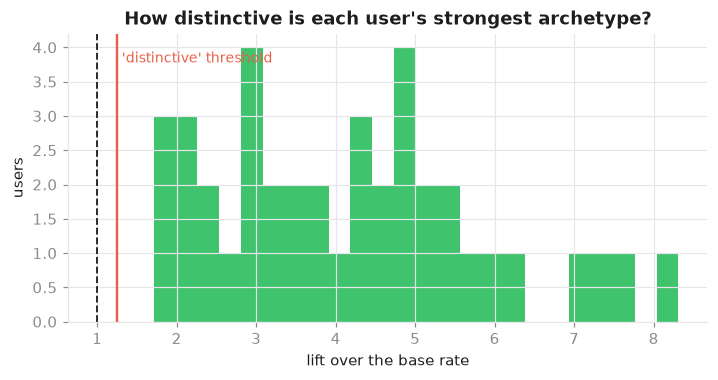

In [11]:
base = A.base_rate(model)
lifts = []
for u in users:
    mix = A.taste_mix(model, listens[listens[S.USER_ID] == u])
    lifts.append(float(A.lift(mix, base).iloc[0]))
lifts = np.array(lifts)

print("archetype model, top-archetype lift over base rate:")
print(f"  median {np.median(lifts):.2f}x   ·   "
      f"users above the 1.25x 'distinctive' bar: {np.mean(lifts >= 1.25):.0%}")
print("")
print(f"for comparison, notebook 01's supervised zodiac model cleared that")
print(f"bar for 27.2% of users. A jump to {np.mean(lifts >= 1.25):.0%} is not a 4x better")
print("feature -- see the note below.")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(lifts, bins=24, color=viz.ACCENT, alpha=.85)
ax.axvline(1.0, color=viz.INK, ls="--", lw=1.2)
ax.axvline(1.25, color=viz.WARN, lw=1.6)
ax.text(1.26, ax.get_ylim()[1]*.9, " 'distinctive' threshold", color=viz.WARN, fontsize=9)
ax.set_title("How distinctive is each user's strongest archetype?")
ax.set_xlabel("lift over the base rate"); ax.set_ylabel("users")
plt.show()

**Do not read that as a win.** Essentially every synthetic user clears the
distinctiveness bar, against 27.2% for the supervised model in notebook 01. A feature
that calls *everyone* distinctive is no more informative than one that calls nobody
distinctive — it has just moved the useless answer to the other end.

The cause is the generator, not the model. `make_users` builds each listener from a
concentrated mixture over a handful of genres, so synthetic users occupy far narrower
regions of audio space than real listeners do, and the archetype mix — which reads audio
space directly — exaggerates that. The supervised model was partly insulated from it
because its labels were noisy enough to wash the concentration out.

So the honest reading is that **this comparison cannot be made on synthetic users at
all.** The distinctiveness threshold has to be recalibrated against real libraries
before it means anything, and until then `is_distinctive` should be treated as
uncalibrated rather than as a shipped guard.

## 5 · The end product

Side by side with notebook 01's version, so the swap is visibly like-for-like. Same
chart, same framing, different thing underneath.

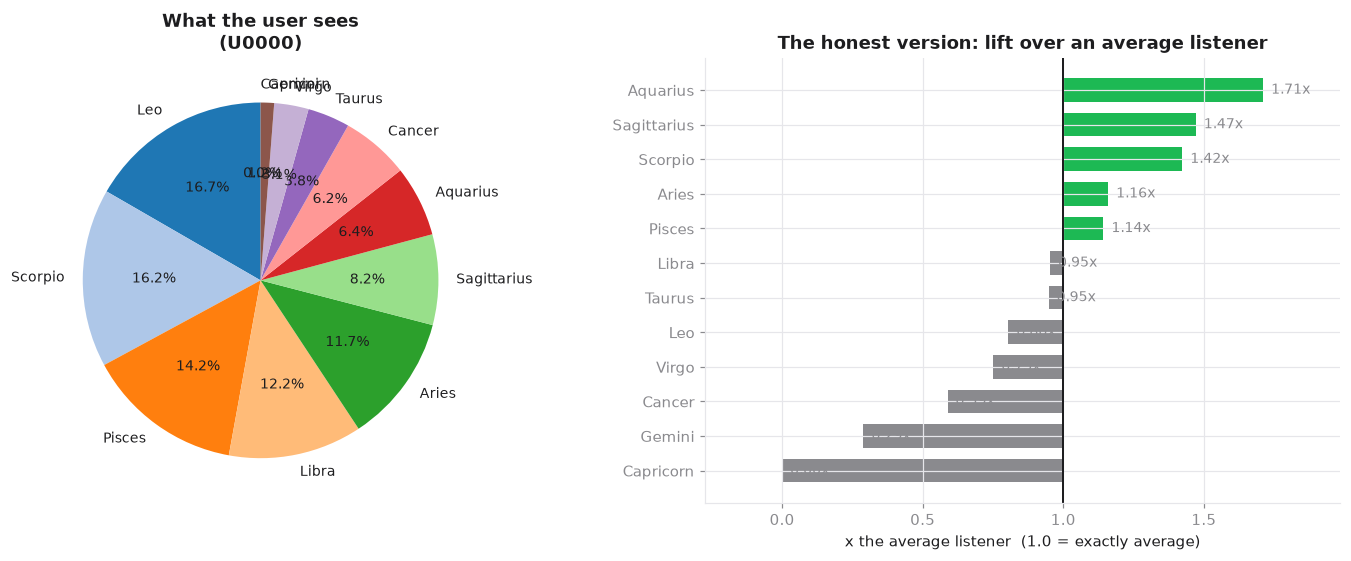

In [12]:
u = users[0]
tracks = listens[listens[S.USER_ID] == u]
mix = A.taste_mix(model, tracks)
lf = A.lift(mix, base)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
viz.taste_mix_pie(mix, f"What the user sees\n({u})", ax=axes[0])
viz.lift_chart(lf, "The honest version: lift over an average listener", ax=axes[1])
plt.tight_layout(); plt.show()

In [13]:
import json
print(json.dumps(A.profile(model, tracks), indent=2)[:900])

{
  "mix": {
    "Leo": 0.1667,
    "Scorpio": 0.1623,
    "Pisces": 0.1424,
    "Libra": 0.1215,
    "Aries": 0.1166,
    "Sagittarius": 0.0822,
    "Aquarius": 0.0643,
    "Cancer": 0.062,
    "Taurus": 0.0384,
    "Virgo": 0.0313,
    "Gemini": 0.0122,
    "Capricorn": 0.0
  },
  "lift": {
    "Aquarius": 1.711,
    "Sagittarius": 1.471,
    "Scorpio": 1.423,
    "Aries": 1.16,
    "Pisces": 1.143,
    "Libra": 0.953,
    "Taurus": 0.948,
    "Leo": 0.805,
    "Virgo": 0.751,
    "Cancer": 0.588,
    "Gemini": 0.289,
    "Capricorn": 0.0
  },
  "headline_sign": "Aquarius",
  "headline_lift": 1.71,
  "is_distinctive": true
}


The payload matches `service.taste_profile`'s shape exactly, including
`is_distinctive`, so swapping the archetype model in behind the Flask route is a
substitution rather than a rewrite.

## Verdict

| | |
|---|---|
| **The label problem** | **Solved, completely.** There are no labels, so there is nothing to leak, no curator disagreement, and no accuracy claim that can be wrong |
| **Reproducibility for a user** | **Solved, conditionally** — fit once and freeze. A frozen model gives identical output every call |
| **Are there twelve kinds of music?** | **No.** The data prefers k=3, separation is weak at every k, and twelve is a product requirement imposed on a continuum |
| **Is the headline archetype robust?** | **No** — it survives a refit 43% of the time. Never retrain casually |
| **One archetype is not music** | Over half spoken-word recordings. Filter non-music genres before fitting |
| **Is it better than supervised zodiac?** | **More defensible, not more powerful** — see below |
| **Is `is_distinctive` calibrated?** | **No.** 100% of synthetic users clear the bar against 27.2% for the supervised model. Recalibrate on real libraries |

### The honest answer to the question this notebook was built to settle

The archetype model is **not more accurate than the supervised classifier, because it is
not making a prediction at all.** It cannot be wrong in the way the classifier is wrong.
That is a real improvement in integrity and it is not an improvement in insight.

What you genuinely gain: a feature that is true by construction, cannot leak, needs no
scraped labels, survives the Spotify deprecation, and can be explained to a sceptical
reviewer in one sentence.

What you do not gain: any evidence that a person's music taste relates to their birth
sign. Nothing here tests that. `SURVEY.md` describes the experiment that would, and the
expected result is a null.

**Recommendation: ship this, framed as a taste fingerprint with playful names.** Fit
once, freeze it, filter the audiobooks out first, and never put an accuracy number next
to it — there isn't one, and that is the point.